- Modelo base com todas as colunas, sem EDA, sem feature selection, sem fine tuning

# 1.0 Imports

In [135]:
import warnings
warnings.filterwarnings("ignore")


In [136]:
# Silencia so uma categoria (ex: avisos de depreciacao)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Silencia so os warnings de uma lib especifica (ex: sklearn/lightgbm)
warnings.filterwarnings("ignore", module="sklearn")


In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np

from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn import preprocessing as pp
from sklearn import metrics as mt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.dummy import DummyClassifier

from scipy import stats

import xgboost as xgb
from lightgbm import LGBMClassifier

# 2.0 Loading Data

In [138]:
# Sobe a partir da pasta atual ate encontrar a raiz do projeto (onde esta pyproject.toml)
def project_root(start: Path = Path.cwd()) -> Path:
    for parent in [start, *start.parents]:
        if (parent / "pyproject.toml").exists():
            return parent
    raise FileNotFoundError("Raiz do projeto (pyproject.toml) nao encontrada")

ROOT = project_root()
DATA_PATH = ROOT / "data" / "HR-Employee-Attrition-balanced.csv"

df_raw = pd.read_csv(DATA_PATH)
df_raw


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,58,Yes,Travel_Rarely,601,Research & Development,7,4,Medical,1,1360,...,4,80,0,31,0,2,10,9,5,9
1,27,Yes,Travel_Frequently,1341,Human Resources,21,2,Human Resources,1,1950,...,1,80,0,0,2,3,0,0,0,0
2,50,Yes,Travel_Rarely,407,Sales,28,3,Marketing,1,2049,...,2,80,1,19,3,2,2,2,1,0
3,39,No,Non-Travel,439,Research & Development,9,3,Life Sciences,1,1132,...,3,80,0,9,2,2,5,4,0,3
4,32,No,Travel_Rarely,601,Sales,7,5,Marketing,1,1446,...,3,80,1,7,3,2,4,3,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1756,35,No,Travel_Rarely,750,Research & Development,28,3,Life Sciences,1,1596,...,4,80,2,10,3,2,10,9,6,8
1757,41,No,Travel_Rarely,447,Research & Development,5,3,Life Sciences,1,1814,...,1,80,0,11,3,1,3,2,1,2
1758,22,Yes,Travel_Frequently,1256,Research & Development,3,4,Life Sciences,1,1203,...,2,80,1,1,5,3,0,0,0,0
1759,29,No,Travel_Rarely,1378,Research & Development,13,2,Other,1,2053,...,1,80,1,10,2,3,4,3,0,3


# 3.0 Data Split - Train + Test

In [ ]:
# Coluna alvo do problema de classificação.
TARGET_COLUMN = "Attrition"

X = df_raw.drop(columns=[TARGET_COLUMN])
y = df_raw[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

# Reconstroi os DataFrames completos de treino e teste.
df_train_total = X_train.join(y_train)
df_test = X_test.join(y_test)

print(f"Treino: {df_train_total.shape[0]} linhas")
print(f"Teste:  {df_test.shape[0]} linhas")
print("\nProporção da variável alvo (treino):")
print(y_train.value_counts(normalize=True))
print("\nProporção da variável alvo (teste):")
print(y_test.value_counts(normalize=True))

## 3.1 Data Split - Train + Val

In [ ]:
df_train_01 = df_train_total.copy()

# Convert response variable from categorial to numerical
df_train_01['Attrition'] = df_train_01["Attrition"].apply(lambda x: 1 if x == "Yes" else 0)

In [ ]:
X_train_total = df_train_01.drop('Attrition', axis=1)
y_train_total = df_train_01['Attrition']

# Train and Validation Split
X_train, X_val, y_train, y_val = train_test_split(X_train_total, y_train_total, test_size=0.20, random_state=42, stratify=y_train_total)

# Reconstroi os DataFrames completos de treino e val.
df_train = X_train.join(y_train) # df_train com y de coluna tambem
df_val = X_val.join(y_val)

print(f"Treino: {df_train.shape[0]} linhas")
print(f"Teste:  {df_val.shape[0]} linhas")
print("\nProporção da variável alvo (treino):")
print(y_val.value_counts(normalize=True))
print("\nProporção da variável alvo (validação):")
print(y_val.value_counts(normalize=True))

# 4.0 Data Cleaning

In [139]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1761 entries, 0 to 1760
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1761 non-null   int64
 1   Attrition                 1761 non-null   str  
 2   BusinessTravel            1761 non-null   str  
 3   DailyRate                 1761 non-null   int64
 4   Department                1761 non-null   str  
 5   DistanceFromHome          1761 non-null   int64
 6   Education                 1761 non-null   int64
 7   EducationField            1761 non-null   str  
 8   EmployeeCount             1761 non-null   int64
 9   EmployeeNumber            1761 non-null   int64
 10  EnvironmentSatisfaction   1761 non-null   int64
 11  Gender                    1761 non-null   str  
 12  HourlyRate                1761 non-null   int64
 13  JobInvolvement            1761 non-null   int64
 14  JobLevel                  1761 non-null   int64
 15

- Dados já vieram tratados - Sem NA e sem colunas para conversão

# 5.0 Data Preparation


- Limpeza de NA
- Transformação das variáveis categóricas
- Transformação das variáveis numéricas (Normalização e Rescala)

## 4.1 Normalização e Rescala de dados númericos

In [143]:
train_num_cols = X_train.select_dtypes( include=['int64', 'float64'] ).columns.tolist()
train_cat_cols = X_train.select_dtypes( include=['object'] ).columns.tolist()

### 4.1.2 Teste de normalidade

In [144]:
results_norm = []
for col in train_num_cols:
    series = X_train[col].dropna()

    # Shapiro-Wilk
    _, sw_p = stats.shapiro( series )

    # Kolmogorov-Smirnov vs normal padronizada
    z = ( series - series.mean() ) / series.std( ddof=0 )
    _, ks_p = stats.kstest( z, 'norm' )

    results_norm.append({
        'Feature': col,
        'Shapiro_p': sw_p,
        'KS_p': ks_p,
        'Normal_alpha_0.05': 'Yes' if (sw_p > 0.05) and (ks_p > 0.05) else 'No'
    })

df_normality = pd.DataFrame( results_norm ).sort_values( by='Shapiro_p', ascending=False )

df_normality.style.format({
    'Shapiro_p': '{:.4f}',
    'KS_p': '{:.4f}'
}).background_gradient( subset=['Shapiro_p', 'KS_p'], cmap='RdYlGn' )

,Feature,Shapiro_p,KS_p,Normal_alpha_0.05
0,Age,0.0000,0.0000,No
12,MonthlyRate,0.0000,0.0001,No
7,HourlyRate,0.0000,0.0001,No
5,EmployeeNumber,0.0000,0.0000,No
1,DailyRate,0.0000,0.0000,No
14,PercentSalaryHike,0.0000,0.0000,No
3,Education,0.0000,0.0000,No
20,TrainingTimesLastYear,0.0000,0.0000,No
19,TotalWorkingYears,0.0000,0.0000,No
23,YearsInCurrentRole,0.0000,0.0000,No


- Shapiro_p ≈ 0.0 (ou < 0.05) → rejeita a hipótese de normalidade → não é normal.
- Normal_alpha_0.05 = 'No' → confirma: não é normal.

- Todas variáveis nao normais - Aplicar um Robust Scaler 

In [145]:
df_train.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
count,1126.000000,1126.000000,1126.000000,1126.000000,1126.0,1126.000000,1126.000000,1126.000000,1126.000000,1126.000000,...,1126.0,1126.00000,1126.000000,1126.000000,1126.000000,1126.000000,1126.000000,1126.000000,1126.000000,1126.00000
mean,36.126110,800.674956,9.475133,2.838366,1.0,1045.992007,2.613677,65.025755,2.580817,1.920959,...,80.0,0.72913,10.591474,2.676732,2.665187,6.596803,3.913854,2.047069,3.821492,0.29929
std,9.225573,407.573816,8.255735,1.070237,0.0,604.658897,1.173390,20.498027,0.819835,1.142304,...,0.0,0.84453,7.837011,1.305145,0.773319,6.292214,3.533289,3.110485,3.548411,0.45815
min,17.000000,97.000000,0.000000,0.000000,1.0,0.000000,0.000000,30.000000,0.000000,0.000000,...,80.0,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,29.250000,443.000000,2.000000,2.000000,1.0,514.500000,2.000000,47.000000,2.000000,1.000000,...,80.0,0.00000,5.000000,2.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.00000
50%,35.000000,791.000000,7.000000,3.000000,1.0,1033.500000,3.000000,64.000000,3.000000,2.000000,...,80.0,1.00000,9.000000,3.000000,3.000000,5.000000,2.000000,1.000000,2.000000,0.00000
75%,42.000000,1167.750000,15.000000,4.000000,1.0,1588.000000,4.000000,83.000000,3.000000,2.000000,...,80.0,1.00000,14.000000,3.000000,3.000000,9.000000,7.000000,2.000000,7.000000,1.00000
max,60.000000,1496.000000,29.000000,5.000000,1.0,2065.000000,4.000000,100.000000,4.000000,5.000000,...,80.0,3.00000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,1.00000


- Exclusao das colunas EmployeeCount e StandardHours por nao possuirem variações

In [146]:
# Dropar colunas EmployeeCount e StandardHours
X_train.drop(['EmployeeCount', 'StandardHours'], axis=1, inplace=True)
X_val.drop(['EmployeeCount', 'StandardHours'], axis=1, inplace=True)

### 4.1.3 Scalers

In [147]:
rs = pp.RobustScaler()

robust_cols = X_train.columns[X_train.dtypes == 'int64'].tolist()

X_train[robust_cols] = rs.fit_transform(X_train[robust_cols])
X_val[robust_cols] = rs.transform(X_val[robust_cols])

## 4.2 Encoders de dados categóricos

In [148]:
# Ver quais os nomes de todas as classes em train_cat_cols

df_train[train_cat_cols].describe().T

,count,unique,top,freq
BusinessTravel,1126,3,Travel_Rarely,794
Department,1126,3,Research & Development,693
EducationField,1126,6,Life Sciences,446
Gender,1126,2,Male,686
JobRole,1126,9,Sales Executive,266
MaritalStatus,1126,3,Married,509
Over18,1126,1,Y,1126
OverTime,1126,2,No,762


- Como temos poucas variações cat. vamos usar nesse primeiro momento o one hot encoding


In [149]:
# Encoder
one_hot_cols = train_cat_cols
ohe = pp.OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='if_binary') # Drop binário dropa colunas 0 ou 1, reduzindo uma coluna, pois coluna de 0 e 1 nao precisam serem convertidas em 2 colunas

X_train_encoded = ohe.fit_transform(X_train[one_hot_cols])

X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=X_train.index
)

X_val_encoded = ohe.transform(X_val[one_hot_cols])
X_val_encoded_df = pd.DataFrame(
    X_val_encoded,
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=X_val.index
)

X_train = pd.concat([X_train.drop(columns=one_hot_cols), X_train_encoded_df], axis=1)
X_val = pd.concat([X_val.drop(columns=one_hot_cols), X_val_encoded_df], axis=1)

# 5.0 Machine Learning Modeling

In [150]:
def ml_metrics( model_name, y_true, y_prob, threshold=0.5):
    y_pred = [ 1 if x > threshold else 0 for x in y_prob ]
    acc = mt.accuracy_score( y_true, y_pred )
    f1 = mt.f1_score( y_true, y_pred, zero_division=0 )
    prec = mt.precision_score( y_true, y_pred, zero_division=0 )
    rec = mt.recall_score( y_true, y_pred, zero_division=0 )
    auc = mt.roc_auc_score( y_true, y_prob )

    return pd.DataFrame({
        'Model Name': model_name,
        'Accuracy': acc,
        'F1-Score': f1,
        'Precision': prec,
        'Recall': rec,
        'AUC': auc
    }, index=[0] )

## 5.1 Baseline Model

O baseline é o **piso de desempenho**: um modelo "burro" que não aprende padrão nenhum dos dados. Ele serve de referência — qualquer modelo de verdade (Logistic Regression, Random Forest, etc.) só justifica sua complexidade se ficar **claramente acima** do baseline.

Usamos o `DummyClassifier` do sklearn, que implementa justamente esses chutes de referência:

- **`strategy='stratified'`**: gera previsões **aleatórias, mas respeitando a proporção das classes do treino**. Como ~30% da base é turnover, ele sorteia "vai sair" com ~30% de probabilidade e "fica" com ~70%. É o equivalente a um chute honesto que conhece só a frequência das classes, nada mais.
- **`fit(X_train, y_train)`**: o Dummy não olha para as features `X` — ele apenas **memoriza a proporção das classes** em `y_train`. É isso que o `fit` faz aqui.
- **`predict_proba(...)[:, 1]`**: retorna a probabilidade da **classe positiva** (sair = 1), no mesmo formato dos outros modelos, para o `ml_metrics` conseguir calcular AUC.
- **`random_state=42`**: fixa a semente do sorteio para o resultado ser **reprodutível** (sem isso, as métricas mudariam a cada execução).

**Como ler o resultado:** espera-se um **AUC próximo de 0.50**, que é a assinatura do acaso — o modelo não separa quem sai de quem fica. Esse 0.50 é a linha de corte: na comparação final, todo modelo útil tem que ter AUC bem acima disso.

> Alternativas de `strategy`: `'most_frequent'` (prevê sempre a classe majoritária — accuracy alta mas **recall 0**, bom para mostrar como accuracy engana em base desbalanceada) e `'prior'` (probabilidade constante igual à taxa de eventos, ~0.30 para todos).

In [151]:
# Definição
# strategy='stratified' -> sorteia respeitando a proporção das classes do treino
# (alternativas: 'prior'/'most_frequent' -> sempre a classe majoritária)
dummy = DummyClassifier(strategy='stratified', random_state=42)

# Treinamento
dummy.fit(X_train, y_train)

# Previsão (probabilidade da classe positiva) no treino e na validação
yhat_baseline_train = dummy.predict_proba(X_train)[:, 1]
yhat_baseline_val = dummy.predict_proba(X_val)[:, 1]

# Desempenho
baseline_train = ml_metrics('Baseline Train', y_train, yhat_baseline_train)
baseline_val = ml_metrics('Baseline Val', y_val, yhat_baseline_val)

baseline = pd.concat( [baseline_train, baseline_val] )
baseline

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Baseline Train,0.564831,0.270833,0.271642,0.270030,0.480389
0,Baseline Val,0.567376,0.298851,0.292135,0.305882,0.493043


## 5.2 Logistic Regression Model

**Regressão Logística** - modelo linear, o mais simples e interpretável dos classificadores.

- **Ideia:** combina as features em uma soma ponderada (`w₁·x₁ + w₂·x₂ + ... + b`) e passa o resultado pela função **sigmoide**, que esmaga qualquer número para o intervalo 0-1, virando probabilidade.
- **O que aprende:** os pesos `w` de cada feature. Peso positivo empurra a probabilidade de sair para cima, negativo para baixo.
- **Fronteira de decisão:** é uma **reta** (ou hiperplano). Só separa bem o que é linearmente separável — não captura interações complexas sozinha.
- **Pré-requisitos:** sensível à escala das features (por isso o scaler importa) e assume que o efeito de cada variável é aproximadamente linear no log-odds.
- **Forças:** rápida, interpretável (dá para ler a importância pelos pesos), ótimo baseline "de verdade".
- **Fraquezas:** limitada em padrões não-lineares; costuma perder para modelos de árvore em dados tabulares complexos.

In [152]:
# Definição
lr_model = LogisticRegression(           # C = 1/λ → inverso da regularização L2
    solver='lbfgs',     # otimizador (quasi-Newton)
    max_iter=1000,      # máximo de iterações
    class_weight = "balanced",
    random_state=42
)

# Treinamento
lr_model.fit(X_train, y_train)

# # Acessar os coeficientes aprendidos
# print("Pesos (W):", lr_model.coef_)
# print("Bias (b):", lr_model.intercept_)
# print("#"*60)

# Previsão
y_hat_lr_train  = lr_model.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_lr_val  = lr_model.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
lr_train = ml_metrics("Logistic Regression Train", y_train, y_hat_lr_train)
lr_val = ml_metrics("Logistic Regression Val", y_val, y_hat_lr_val)

lr = pd.concat([lr_train, lr_val])
lr

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Logistic Regression Train,0.859680,0.783562,0.727735,0.848665,0.931044
0,Logistic Regression Val,0.815603,0.717391,0.666667,0.776471,0.906360


## 5.3 Random Forest Model

**Random Forest** - ensemble de muitas árvores de decisão treinadas **em paralelo** (técnica de *bagging*).

- **Ideia:** treina N árvores independentes, cada uma em uma amostra aleatória dos dados (*bootstrap*) e usando um subconjunto aleatório de features. A previsão final é a **média/voto** de todas as árvores.
- **Por que funciona:** cada árvore sozinha erra de um jeito diferente; ao combinar muitas, os erros aleatórios se cancelam e **reduz a variância** (menos overfitting que uma árvore só).
- **Fronteira de decisão:** não-linear, feita de cortes retangulares - captura interações entre variáveis sem precisar que você as crie na mão.
- **Escala:** **não precisa** de normalização - árvores só comparam "maior/menor que um limiar".
- **Forças:** robusta, pouca necessidade de tuning, lida bem com features irrelevantes, dá importância de variáveis.
- **Fraquezas:** modelo "caixa-preta" (menos interpretável), pode ficar pesado em memória, e com árvores sem limite de profundidade memoriza o treino (veja o train = 1.0).

In [153]:
# Definição
rf = RandomForestClassifier(
    n_jobs=-1, 
    n_estimators = 100,
    class_weight = 'balanced',
    random_state=42)

# Treinamento
rf.fit(X_train, y_train)

# Previsão
y_hat_rf_train  = rf.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_rf_val  = rf.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
rf_train = ml_metrics("Random Forest Train", y_train, y_hat_rf_train, threshold=0.5)
rf_val = ml_metrics("Random Forest Val", y_val, y_hat_rf_val, threshold=0.5)

rf = pd.concat([rf_train, rf_val])
rf

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Random Forest Train,1.000000,1.0,1.000000,1.000000,1.0000
0,Random Forest Val,0.886525,0.8,0.853333,0.752941,0.9298


## 5.4 XGBoost Model

**XGBoost** - ensemble de árvores treinadas **em sequência** (técnica de *boosting*).

- **Ideia:** ao contrário da Random Forest (paralela), aqui cada nova árvore é treinada para **corrigir os erros** (resíduos) das árvores anteriores. O modelo vai refinando a previsão passo a passo.
- **Como aprende:** usa o **gradiente** da função de perda para saber onde está errando e quanto corrigir; cada árvore é somada ao conjunto com um peso pequeno (*learning rate*) para aprender devagar e não exagerar.
- **Foco:** reduz o **viés** (bias) - aprende padrões difíceis que modelos simples não pegam.
- **Escala:** não precisa de normalização (é baseado em árvores).
- **Forças:** costuma ser o **melhor desempenho** em dados tabulares; regularização embutida; trata valores ausentes nativamente.
- **Fraquezas:** mais sensível a overfitting (precisa de tuning cuidadoso), treino mais lento que a RF por ser sequencial, muitos hiperparâmetros.

- Parametro class_weight = 'balanced' ó existe em lib do sklearn, xgboost é outra lib, e só aceita o scale pos weight.

In [154]:
ratio = float((y_train == 0).sum() / (y_train == 1).sum()) # Proporção das classes para evitar overvitting

# Definição
xgb_model = xgb.XGBClassifier(
    random_state=42,
    scale_pos_weight = ratio,
    n_jobs=-1
)

# Treinamento
xgb_model.fit(X_train, y_train)

# Previsão
y_hat_xgboost_train  = xgb_model.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_xgboost_val  = xgb_model.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
xgboost_train = ml_metrics("XGBOOST Train", y_train, y_hat_xgboost_train)
xgboost_val = ml_metrics("XGBOOST Val", y_val, y_hat_xgboost_val)

xgboost = pd.concat([xgboost_train, xgboost_val])
xgboost

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,XGBOOST Train,1.000000,1.000000,1.000000,1.000000,1.000000
0,XGBOOST Val,0.875887,0.779874,0.837838,0.729412,0.915557


## 5.5 LGBM Model

**LightGBM** - também é *gradient boosting* de árvores (mesma família do XGBoost), mas otimizado para ser **mais rápido**.

- **Mesma ideia do XGBoost:** árvores em sequência, cada uma corrigindo os erros da anterior via gradiente.
- **Diferença principal:** cresce as árvores por **folha** (*leaf-wise*), expandindo sempre a folha que mais reduz o erro, enquanto o XGBoost cresce por **nível**. Isso o deixa mais rápido e geralmente mais preciso, mas com maior risco de overfitting em bases pequenas.
- **Truques de velocidade:** agrupa valores contínuos em *bins* (histogramas), o que acelera muito a busca pelo melhor corte.
- **Escala:** não precisa de normalização (árvores).
- **Forças:** treino muito veloz, ótimo com datasets grandes e muitas features; aceita `class_weight='balanced'` nativamente.
- **Fraquezas:** o crescimento *leaf-wise* pode overfittar em bases pequenas (controle com `num_leaves`, `min_child_samples`); sensível a tuning como o XGBoost.

- o LightGBM aceita class_weight='balanced' de verdade (ele implementou esse parâmetro)

In [155]:
# Definição
lgbm = LGBMClassifier(
    class_weight = 'balanced',
    metric='auc',
    n_jobs=-1,
    random_state=42,
    verbose=-1
)

# Treinamento
lgbm.fit(X_train, y_train)


# Previsão
y_hat_lgbm_train  = lgbm.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_lgbm_val  = lgbm.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
lgbm_train = ml_metrics("LGBM Train", y_train, y_hat_lgbm_train)
lgbm_val = ml_metrics("LGBM Val", y_val, y_hat_lgbm_val)

lgbm = pd.concat([lgbm_train, lgbm_val])
lgbm

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,LGBM Train,1.000000,1.000000,1.000000,1.000000,1.000000
0,LGBM Val,0.882979,0.789809,0.861111,0.729412,0.913168


# 5.0 Model Comparison

In [160]:
print("------ Training metrics --------")
display(pd.concat([baseline_train, lr_train, rf_train, xgboost_train, lgbm_train], ignore_index=True))


print("------ Validation metrics --------")
display(pd.concat([baseline_val, lr_val, rf_val, xgboost_val, lgbm_val], ignore_index=True))

------ Training metrics --------


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Baseline Train,0.564831,0.270833,0.271642,0.270030,0.480389
1,Logistic Regression Train,0.859680,0.783562,0.727735,0.848665,0.931044
2,Random Forest Train,1.000000,1.000000,1.000000,1.000000,1.000000
3,XGBOOST Train,1.000000,1.000000,1.000000,1.000000,1.000000
4,LGBM Train,1.000000,1.000000,1.000000,1.000000,1.000000


------ Validation metrics --------


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Baseline Val,0.567376,0.298851,0.292135,0.305882,0.493043
1,Logistic Regression Val,0.815603,0.717391,0.666667,0.776471,0.906360
2,Random Forest Val,0.886525,0.800000,0.853333,0.752941,0.929800
3,XGBOOST Val,0.875887,0.779874,0.837838,0.729412,0.915557
4,LGBM Val,0.882979,0.789809,0.861111,0.729412,0.913168


# 6.0 Models Evaluation - Best Threshold

- Para RandomForest

In [157]:
# Calcular a curva
precisions, recalls, thresholds = mt.precision_recall_curve(y_val, y_hat_rf_val)
av_precision = mt.average_precision_score(y_val, y_hat_rf_val)
baseline = y_val.mean()  # precision de um modelo aleatório

print(f"Average Precision (AUC-PR): {av_precision:.4f}")
print(f"Baseline (taxa de eventos): {baseline:.4f}")
print(f"Ganho sobre baseline:       {av_precision/baseline:.2f}x")

Average Precision (AUC-PR): 0.8946
Baseline (taxa de eventos): 0.3014
Ganho sobre baseline:       2.97x


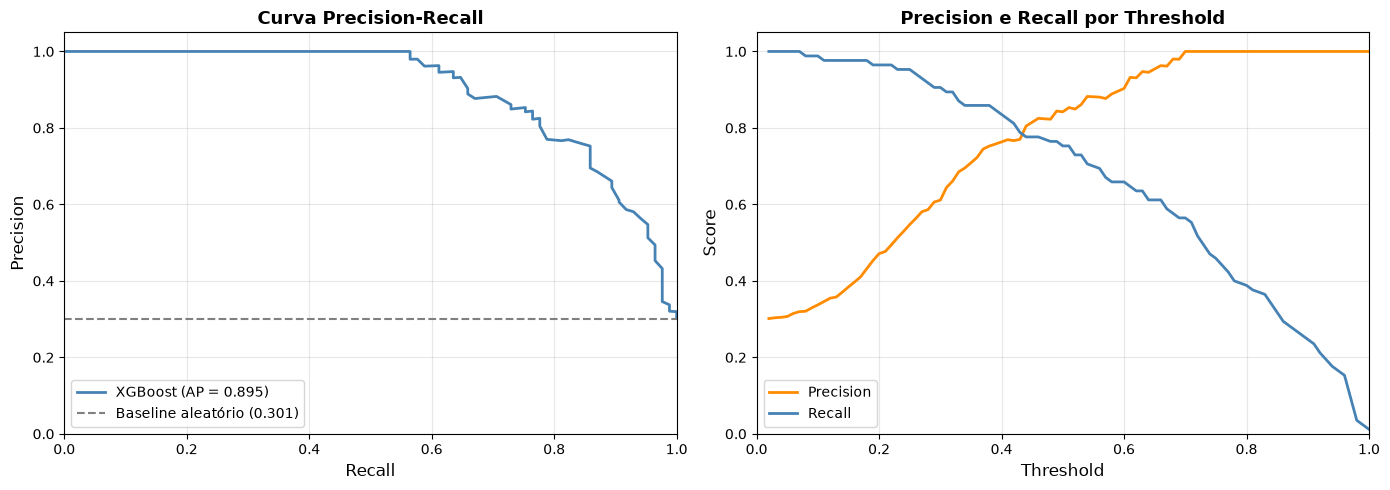

In [158]:
# Plotar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Curva PR ---
ax1 = axes[0]
ax1.plot(recalls, precisions, color='steelblue', lw=2,
         label=f'XGBoost (AP = {av_precision:.3f})')
ax1.axhline(y=baseline, color='gray', linestyle='--', lw=1.5,
            label=f'Baseline aleatório ({baseline:.3f})')
ax1.set_xlabel('Recall', fontsize=12)
ax1.set_ylabel('Precision', fontsize=12)
ax1.set_title('Curva Precision-Recall', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1.05])
ax1.grid(alpha=0.3)

# --- Precision e Recall por threshold ---
ax2 = axes[1]
ax2.plot(thresholds, precisions[:-1], color='darkorange', lw=2, label='Precision')
ax2.plot(thresholds, recalls[:-1],    color='steelblue',  lw=2, label='Recall')
ax2.set_xlabel('Threshold', fontsize=12)
ax2.set_ylabel('Score', fontsize=12)
ax2.set_title('Precision e Recall por Threshold', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1.05])
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('precision_recall_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [159]:
# -------------------------------------------------------
# Critério 1: maximizar F1-Score
# (equilíbrio harmônico entre Precision e Recall)
# -------------------------------------------------------
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (
    precisions[:-1] + recalls[:-1] + 1e-10
)
best_idx_f1 = np.argmax(f1_scores)
threshold_f1 = thresholds[best_idx_f1]

print("=== Threshold ótimo pelo F1-Score ===")
print(f"Threshold:  {threshold_f1:.4f}")
print(f"F1-Score:   {f1_scores[best_idx_f1]:.4f}")
print(f"Precision:  {precisions[best_idx_f1]:.4f}")
print(f"Recall:     {recalls[best_idx_f1]:.4f}")

# -------------------------------------------------------
# Critério 2: Recall mínimo garantido pelo negócio
# Ex: "quero capturar pelo menos 80% dos fraudes"
# -------------------------------------------------------
recall_minimo = 0.80
mask_recall = recalls[:-1] >= recall_minimo
if mask_recall.any():
    # Dentre os thresholds que atingem o recall mínimo,
    # escolher o que maximiza Precision
    precisions_filtradas = np.where(mask_recall, precisions[:-1], 0)
    best_idx_recall = np.argmax(precisions_filtradas)
    threshold_recall = thresholds[best_idx_recall]

    print(f"\n=== Threshold com Recall ≥ {recall_minimo} ===")
    print(f"Threshold:  {threshold_recall:.4f}")
    print(f"Precision:  {precisions[best_idx_recall]:.4f}")
    print(f"Recall:     {recalls[best_idx_recall]:.4f}")
    print(f"F1-Score:   {f1_scores[best_idx_recall]:.4f}")

# -------------------------------------------------------
# Critério 3: Precision mínima garantida pelo negócio
# Ex: "quero que pelo menos 70% dos alertas sejam verdadeiros"
# -------------------------------------------------------
precision_minima = 0.70
mask_prec = precisions[:-1] >= precision_minima
if mask_prec.any():
    recalls_filtrados = np.where(mask_prec, recalls[:-1], 0)
    best_idx_prec = np.argmax(recalls_filtrados)
    threshold_prec = thresholds[best_idx_prec]

    print(f"\n=== Threshold com Precision ≥ {precision_minima} ===")
    print(f"Threshold:  {threshold_prec:.4f}")
    print(f"Precision:  {precisions[best_idx_prec]:.4f}")
    print(f"Recall:     {recalls[best_idx_prec]:.4f}")
    print(f"F1-Score:   {f1_scores[best_idx_prec]:.4f}")

=== Threshold ótimo pelo F1-Score ===
Threshold:  0.4900
F1-Score:   0.8025
Precision:  0.8442
Recall:     0.7647

=== Threshold com Recall ≥ 0.8 ===
Threshold:  0.4100
Precision:  0.7692
Recall:     0.8235
F1-Score:   0.7955

=== Threshold com Precision ≥ 0.7 ===
Threshold:  0.3500
Precision:  0.7087
Recall:     0.8588
F1-Score:   0.7766
